#  Comprehensive Solar Energetic Electron event Catalogue (CoSEE-Cat), Data Release 1
This notebook is set up to analyse the CoSEE-Cat DR1 dataset (see Warmuth 2025).

This notebook reads in the CoSEE-cat .csv, and finds the solar energetic electron events that are not associated with a STIX X-ray flare. 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

path = Path(r"C:\Users\pauls\SEPs\coseecat_dr1\data\CoSEE_full.csv")
print(path.exists(), f"{path.stat().st_size / 1e6:.2f} MB")

True 0.13 MB


In [2]:
# look at the raw text file first

with open(path, "r", encoding="utf-8", errors="replace") as f:
    for i, line in enumerate(f):
        print(i, line[:300].rstrip())
        if i >= 15:
            break
        

0 event_id,event_date,solo_dist,solo_lon,solo_lat,epd_tonset,epd_delta_t,epd_tpeak,epd_ipeak,epd_epeak,tsa_itime,vda_itime,vda_time_unc,vda_lpath,vda_path_unc,nominal_path,epd_aniso,epd_compo,epd_series,epd_dispersive,goes_class,goes_estim,stix_status,stix_tpeak,stix_emax,stix_tpeak_epd,stix_tpeak_rpw
1 2011170942,2020-11-17,0.928,122.2,-6.0,2020-11-17T09:42:30,60,2020-11-17T10:21:30,3.42E+04,43,2020-11-17T09:27:27,,,,,1.06,large,impulsive,Y,,,C1,1,2020-11-17T09:32:45,25.0,2020-11-17T09:26:49,,929.0,-285,-18.1,-167.1,340.6,12786,2,1,969.0,-317.0,-18.8,-156.3,351.4,12786,flare,510.0,628.0,32.4,157.8
2 2011171841,2020-11-17,0.926,122.1,-6.0,2020-11-17T18:41:30,60,2020-11-17T18:48:30,2.70E+04,43,2020-11-17T18:26:29,2020-11-17T18:25:24,0.9,1.15,0.03,1.06,large,impulsive,Y,Y,,B6,1,2020-11-17T18:26:57,15.0,2020-11-17T18:26:57,2020-11-17T18:26:57,949.0,-383,-22.6,-154.9,347.9,12786,1,1,983.0,-267.0,-16
3 2011181056,2020-11-18,0.924,122.1,-6.0,2020-11-18T10:56:30,60,,,24,2020-11-18T10:34:33,,,

In [3]:
# Read in the file

df = pd.read_csv(path)
# If Cell 2 shows comment lines, use:  pd.read_csv(path, comment="#")
# If it shows fill values such as -9999: pd.read_csv(path, na_values=[-9999, "-9999"])

print(df.shape)
df.head()

(303, 99)


,event_id,event_date,solo_dist,solo_lon,solo_lat,epd_tonset,epd_delta_t,epd_tpeak,epd_ipeak,epd_epeak,...,ss_fr_delay,sw_condition,mag_polarity,ip_complex,ip_confidence,conn_carr_lon,conn_lon_unc,conn_hgs_lat,conn_lat_unc,conn_conf
0,2011170942,2020-11-17,0.928,122.2,-6.0,2020-11-17T09:42:30,60,2020-11-17T10:21:30,34200.0,43.0,...,30.0,NaN,NaN,n,2,333.28,4.00,-30.77,5.75,3
1,2011171841,2020-11-17,0.926,122.1,-6.0,2020-11-17T18:41:30,60,2020-11-17T18:48:30,27000.0,43.0,...,20.0,NaN,NaN,n,2,332.29,6.50,-31.22,9.25,3
2,2011181056,2020-11-18,0.924,122.1,-6.0,2020-11-18T10:56:30,60,NaN,NaN,24.0,...,4.0,NaN,NaN,y,2,329.34,3.16,-31.16,3.41,3
3,2011181214,2020-11-18,0.924,122.1,-6.0,2020-11-18T12:14:30,60,2020-11-18T12:15:30,2900.0,43.0,...,3.0,NaN,NaN,y,2,329.34,3.16,-31.16,3.41,3
4,2011181331,2020-11-18,0.924,122.1,-6.0,2020-11-18T13:31:30,60,2020-11-18T13:41:30,7640.0,43.0,...,2.0,NaN,NaN,y,2,329.34,3.16,-31.16,3.41,3


In [4]:
# Structure overview
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 99 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   event_id           303 non-null    int64  
 1   event_date         303 non-null    str    
 2   solo_dist          303 non-null    float64
 3   solo_lon           303 non-null    float64
 4   solo_lat           303 non-null    float64
 5   epd_tonset         303 non-null    str    
 6   epd_delta_t        303 non-null    int64  
 7   epd_tpeak          300 non-null    str    
 8   epd_ipeak          300 non-null    float64
 9   epd_epeak          303 non-null    float64
 10  tsa_itime          303 non-null    str    
 11  vda_itime          126 non-null    str    
 12  vda_time_unc       126 non-null    float64
 13  vda_lpath          126 non-null    float64
 14  vda_path_unc       126 non-null    float64
 15  nominal_path       303 non-null    float64
 16  epd_aniso          226 non-null    st

In [5]:
# Columns and missing data

summary = pd.DataFrame({
    "dtype": df.dtypes,
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(1),
    "n_unique": df.nunique(),
})
summary

,dtype,n_missing,pct_missing,n_unique
event_id,int64,0,0.0,303
event_date,str,0,0.0,149
solo_dist,float64,0,0.0,210
solo_lon,float64,0,0.0,197
solo_lat,float64,0,0.0,97
...,...,...,...,...
conn_carr_lon,float64,0,0.0,206
conn_lon_unc,float64,0,0.0,116
conn_hgs_lat,float64,0,0.0,199
conn_lat_unc,float64,0,0.0,129


In [6]:
# check stix_status

df["stix_status"].value_counts().sort_index()

stix_status
0     15
1    288
Name: count, dtype: int64

In [7]:
def stix_category(r):
    if pd.isna(r["stix_tpeak"]):
        return "no flare time (a or b)"
    if pd.isna(r["stix_hgs_lat"]):
        return "c) flare, no position"
    return "flare + position"

df["stix_cat"] = df.apply(stix_category, axis=1)
pd.crosstab(df["stix_cat"], df["stix_status"], margins=True)

stix_status,0,1,All
stix_cat,,,
"c) flare, no position",0,63,63
flare + position,0,205,205
no flare time (a or b),15,20,35
All,15,288,303


In [8]:
cols = ["event_id", "event_date", "stix_status", "stix_tpeak", "stix_emax",
        "goes_estim", "stix_epd_qual", "eui_status", "rpw_status"]
df.loc[df["stix_cat"] == "no flare time (a or b)", cols].sort_values("stix_status")

,event_id,event_date,stix_status,stix_tpeak,stix_emax,goes_estim,stix_epd_qual,eui_status,rpw_status
8,2011240701,2020-11-24,0,NaN,NaN,NaN,3,0,1
9,2011241331,2020-11-24,0,NaN,NaN,NaN,3,0,1
10,2011241735,2020-11-24,0,NaN,NaN,NaN,3,0,1
11,2011291337,2020-11-29,0,NaN,NaN,NaN,3,0,1
13,2012100809,2020-12-10,0,NaN,NaN,NaN,3,0,1
12,2012100748,2020-12-10,0,NaN,NaN,NaN,3,0,1
14,2012101344,2020-12-10,0,NaN,NaN,NaN,3,0,1
15,2012102049,2020-12-10,0,NaN,NaN,NaN,3,0,1
19,2012130951,2020-12-13,0,NaN,NaN,NaN,3,0,1
16,2012102346,2020-12-10,0,NaN,NaN,NaN,3,0,1


In [9]:
cols = ["event_id", "event_date", "stix_status", "stix_epd_qual",
        "stix_tpeak_epd", "stix_emax", "goes_estim", "eui_status", "rpw_status"]
no_flare = df[df["stix_cat"] == "no flare time (a or b)"]
no_flare[cols].sort_values(["stix_status", "event_date"])

,event_id,event_date,stix_status,stix_epd_qual,stix_tpeak_epd,stix_emax,goes_estim,eui_status,rpw_status
8,2011240701,2020-11-24,0,3,NaN,NaN,NaN,0,1
9,2011241331,2020-11-24,0,3,NaN,NaN,NaN,0,1
10,2011241735,2020-11-24,0,3,NaN,NaN,NaN,0,1
11,2011291337,2020-11-29,0,3,NaN,NaN,NaN,0,1
12,2012100748,2020-12-10,0,3,NaN,NaN,NaN,0,1
13,2012100809,2020-12-10,0,3,NaN,NaN,NaN,0,1
14,2012101344,2020-12-10,0,3,NaN,NaN,NaN,0,1
15,2012102049,2020-12-10,0,3,NaN,NaN,NaN,0,1
16,2012102346,2020-12-10,0,3,NaN,NaN,NaN,0,1
17,2012111055,2020-12-11,0,3,NaN,NaN,NaN,0,1


In [10]:
pd.crosstab(no_flare["stix_status"], no_flare["stix_epd_qual"])

stix_epd_qual,3
stix_status,
0,15
1,20


In [11]:
for status, dates in no_flare.groupby("stix_status")["event_date"]:
    print(f"\nstix_status = {status} ({len(dates)} events)")
    print(sorted(dates.tolist()))


stix_status = 0 (15 events)
['2020-11-24', '2020-11-24', '2020-11-24', '2020-11-29', '2020-12-10', '2020-12-10', '2020-12-10', '2020-12-10', '2020-12-10', '2020-12-11', '2020-12-11', '2020-12-13', '2021-04-19', '2022-04-28', '2022-04-28']

stix_status = 1 (20 events)
['2020-11-20', '2021-02-14', '2021-05-24', '2021-05-24', '2021-05-24', '2021-05-28', '2021-07-16', '2021-07-18', '2021-12-04', '2021-12-05', '2022-03-18', '2022-03-19', '2022-05-03', '2022-10-18', '2022-10-29', '2022-10-29', '2022-10-29', '2022-10-30', '2022-12-24', '2022-12-24']


In [12]:
pd.crosstab(df["stix_cat"], df["stix_epd_qual"], margins=True)

stix_epd_qual,1,2,3,All
stix_cat,,,,
"c) flare, no position",43,16,4,63
flare + position,96,104,5,205
no flare time (a or b),0,0,35,35
All,139,120,44,303


In [13]:
# Catalague also uses EUI for flare location. 

needs = df[df["stix_hgs_lat"].isna()].copy()
print(len(needs))

needs["has_eui"] = needs["eui_hgs_lat1"].notna()
pd.crosstab(needs["stix_cat"], needs["has_eui"], margins=True)

98


has_eui,False,True,All
stix_cat,,,
"c) flare, no position",21,42,63
no flare time (a or b),22,13,35
All,43,55,98


In [14]:
# Do STIX and EUI agree where both exist? Stonyhurst coordinates

both = df[df["stix_hgs_lat"].notna() & df["eui_hgs_lat1"].notna()]
print(len(both))
print((both["eui_hgs_lon1"] - both["stix_hgs_lon"]).describe())
print((both["eui_hgs_lat1"] - both["stix_hgs_lat"]).describe())

130
count    130.000000
mean       1.246923
std       34.228120
min     -103.400000
25%       -2.200000
50%       -0.200000
75%        0.975000
max      351.200000
dtype: float64
count    130.000000
mean       0.650000
std        9.127021
min      -45.700000
25%       -0.600000
50%        0.400000
75%        1.700000
max       49.700000
dtype: float64


In [15]:
df["eui_type1"].value_counts(dropna=False)

eui_type1
NaN                                                  109
flare                                                 88
flare, jet                                            59
flare, erupting filament                              11
flare, loop opening                                    9
flare, fan-like eruption                               9
erupting filament                                      2
flare, loop-like eruption                              2
flare, loop-like eruption, fan-like eruption           2
flare, jet, loop opening                               2
flare,  loop opening                                   1
loop opening                                           1
jet                                                    1
flare, erupting filament, loop-like eruption           1
flare, loop-like eruption                              1
flare, loop opening, fan-like eruption                 1
flare, loop-opening                                    1
flare, loop-like     

In [16]:
# Do STIX and EUI agree where both exist? Carrington coordinates

stix_col = "stix_carr_lon"   # whatever the real names are
eui_col = "eui_carr_lon1"

both = df[df[stix_col].notna() & df[eui_col].notna()].copy()
print(len(both))

dlon = both[eui_col] - both[stix_col]
dlon = (dlon + 180) % 360 - 180   # wrap into [-180, 180)
print(dlon.describe())

130
count    130.000000
mean      -1.793846
std       14.675586
min     -103.600000
25%       -2.500000
50%       -0.400000
75%        0.700000
max       80.100000
dtype: float64


9 events with |dlon| > 10 deg
5 events with |dlon| > 30 deg
median: -0.4000000000000057  robust sigma: 2.2980300000000167
     stix_carr_lon  eui_carr_lon1   dlon
225          167.0           63.4 -103.6
101          326.1           46.2   80.1
219          131.6           63.5  -68.1
105          302.5          250.1  -52.4
106          336.8           18.9   42.1
193          106.0           87.9  -18.1
166          322.2          309.5  -12.7
0            340.6          351.4   10.8
128          112.6          102.0  -10.6
120          114.2          105.2   -9.0
182          294.2          302.7    8.5
189          108.0           99.7   -8.3
2            343.5          336.2   -7.3
117           84.0           76.7   -7.3
125          114.5          107.3   -7.2


<Axes: >

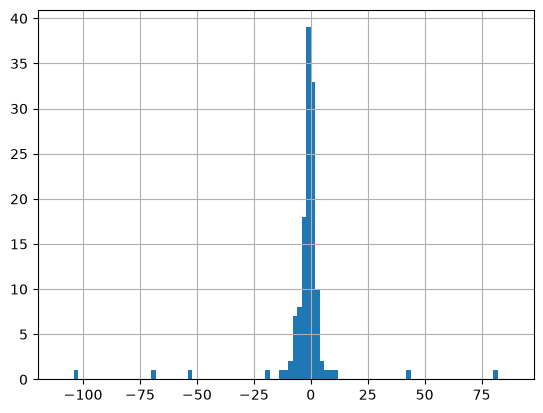

In [17]:
# look at the outliers

both = both.assign(dlon=dlon)

print((dlon.abs() > 10).sum(), "events with |dlon| > 10 deg")
print((dlon.abs() > 30).sum(), "events with |dlon| > 30 deg")

# robust scatter (MAD scaled to be comparable to a Gaussian sigma)
mad = (dlon - dlon.median()).abs().median() * 1.4826
print("median:", dlon.median(), " robust sigma:", mad)

# inspect the worst cases
cols = ["stix_carr_lon", "eui_carr_lon1", "dlon"]  # add date/ID columns here
print(both.loc[dlon.abs().sort_values(ascending=False).index[:15], cols])

dlon.hist(bins=np.arange(-110, 90, 2))

In [18]:
# Look at statistics excluding 6 outliers

core = dlon[(dlon > -13) & (dlon < 11)]   # or: dlon.drop(outlier_index)
print(len(core))
print(core.describe())

124
count    124.000000
mean      -0.912903
std        3.452016
min      -12.700000
25%       -2.400000
50%       -0.400000
75%        0.700000
max       10.800000
dtype: float64


In [19]:
# print a list of all 6 outliers

out = both[(dlon < -13) | (dlon > 11)]
print(out[["stix_carr_lon", "eui_carr_lon1", "dlon"]])   # plus date/ID, flags, eui_carr_lon2 etc.

     stix_carr_lon  eui_carr_lon1   dlon
101          326.1           46.2   80.1
105          302.5          250.1  -52.4
106          336.8           18.9   42.1
193          106.0           87.9  -18.1
219          131.6           63.5  -68.1
225          167.0           63.4 -103.6


In [20]:
# df containing event ID and date, and STIX and EUI longitudes in Carrington coords, and the difference in long between STIX and EUI
both = both.assign(dlon=dlon)

cols = ["event_id", "event_date",
        "stix_carr_lon", "eui_carr_lon1", "eui_carr_lon2", "eui_carr_lon3", "dlon"]

outliers = both.loc[(both["dlon"] < -13) | (both["dlon"] > 11), cols].copy()

# offsets for the second and third EUI positions, wrapped into [-180, 180)
for n in (2, 3):
    d = outliers[f"eui_carr_lon{n}"] - outliers["stix_carr_lon"]
    outliers[f"dlon{n}"] = (d + 180) % 360 - 180

print(len(outliers))   # should be 6
print(outliers)

6
       event_id  event_date  stix_carr_lon  eui_carr_lon1  eui_carr_lon2  eui_carr_lon3   dlon  dlon2  dlon3
101  2203060804  2022-03-06          326.1           46.2            NaN            NaN   80.1    NaN    NaN
105  2203091432  2022-03-09          302.5          250.1            7.2            NaN  -52.4   64.7    NaN
106  2203091559  2022-03-09          336.8           18.9            NaN            NaN   42.1    NaN    NaN
193  2209230459  2022-09-23          106.0           87.9            NaN            NaN  -18.1    NaN    NaN
219  2210290731  2022-10-29          131.6           63.5            NaN            NaN  -68.1    NaN    NaN
225  2210291912  2022-10-29          167.0           63.4            NaN            NaN -103.6    NaN    NaN


In [21]:
# Now look at the 43 events that dont have STIX or EUI
# columns that might hold any kind of position
pos_cols = [c for c in df.columns
            if any(k in c.lower() for k in ["lon", "lat", "carr", "hgs", "hpc", "loc", "pos", "region", "ar", "noaa"])]
print(pos_cols)

['solo_lon', 'solo_lat', 'stix_hpc_x', 'stix_hpc_y', 'stix_hgs_lat', 'stix_hgs_lon', 'stix_carr_lon', 'stix_ar_num', 'eui_hpc_x1', 'eui_hpc_y1', 'eui_hgs_lat1', 'eui_hgs_lon1', 'eui_carr_lon1', 'eui_ar_num1', 'eui_hpc_x2', 'eui_hpc_y2', 'eui_hgs_lat2', 'eui_hgs_lon2', 'eui_carr_lon2', 'eui_ar_num2', 'eui_hpc_x3', 'eui_hpc_y3', 'eui_hgs_lat3', 'eui_hgs_lon3', 'eui_carr_lon3', 'eui_ar_num3', 'metis_tstart1', 'metis_tstart2', 'solohi_tstart', 'post_icme_delay', 'sir_rar_delay', 'mag_polarity', 'conn_carr_lon', 'conn_lon_unc', 'conn_hgs_lat', 'conn_lat_unc']


In [22]:
# events with no STIX and no EUI Carrington longitude
no_pos = df[df["stix_carr_lon"].isna() & df["eui_carr_lon1"].isna()].copy()
print(len(no_pos))   # should be 43

# consistency check: do any of them have STIX/EUI positions in other columns?
check_cols = ["stix_hgs_lon", "stix_hgs_lat", "eui_hgs_lon1", "eui_hgs_lat1"]
print(no_pos[check_cols].notna().sum())

# how many have any position-like value in the other columns you found?
print(no_pos[pos_cols].notna().sum().sort_values(ascending=False))

43
stix_hgs_lon    0
stix_hgs_lat    0
eui_hgs_lon1    0
eui_hgs_lat1    0
dtype: int64
solo_lon           43
solo_lat           43
conn_hgs_lat       43
conn_lat_unc       43
conn_lon_unc       43
conn_carr_lon      43
mag_polarity       28
eui_ar_num1         5
metis_tstart1       5
sir_rar_delay       4
post_icme_delay     1
stix_hpc_x          0
stix_hpc_y          0
stix_hgs_lat        0
stix_carr_lon       0
stix_hgs_lon        0
eui_hpc_x1          0
eui_hpc_y1          0
eui_hgs_lat1        0
stix_ar_num         0
eui_ar_num2         0
eui_carr_lon2       0
eui_hgs_lon2        0
eui_hgs_lat2        0
eui_hpc_y2          0
eui_hpc_x2          0
eui_carr_lon1       0
eui_hgs_lon1        0
metis_tstart2       0
eui_ar_num3         0
eui_carr_lon3       0
eui_hgs_lon3        0
eui_hpc_y3          0
eui_hgs_lat3        0
eui_hpc_x3          0
solohi_tstart       0
dtype: int64


In [23]:
# compare simple properties: replace with the real column names
props = ["event_date", "goes_class", "solo_dist"]   # whatever exists
for p in props:
    print(p)
    print("no position:", no_pos[p].describe())
    print("has position:", df.drop(no_pos.index)[p].describe())

event_date
no position: count             43
unique            31
top       2020-12-10
freq               5
Name: event_date, dtype: object
has position: count            260
unique           129
top       2022-10-29
freq              17
Name: event_date, dtype: object
goes_class
no position: count        3
unique       2
top       B1.8
freq         2
Name: goes_class, dtype: object
has position: count       94
unique      63
top       C2.2
freq         4
Name: goes_class, dtype: object
solo_dist
no position: count    43.000000
mean      0.794512
std       0.176460
min       0.326000
25%       0.730000
50%       0.854000
75%       0.925000
max       1.010000
Name: solo_dist, dtype: float64
has position: count    260.000000
mean       0.685173
std        0.211011
min        0.313000
25%        0.479250
50%        0.649000
75%        0.901750
max        1.015000
Name: solo_dist, dtype: float64


In [24]:
def wrap(x):
    return (x + 180) % 360 - 180

sub = df[df["stix_hgs_lon"].notna()].copy()
sub["flare_rel"] = wrap(sub["stix_hgs_lon"] - sub["solo_lon"])
print(sub["flare_rel"].abs().describe())
print((sub["flare_rel"].abs() > 90).sum(), "events beyond 90 deg")

count    205.000000
mean      53.337073
std       25.885002
min        0.700000
25%       34.200000
50%       52.000000
75%       77.300000
max       89.700000
Name: flare_rel, dtype: float64
0 events beyond 90 deg


In [25]:
import numpy as np
import pandas as pd
from astropy.time import Time
from sunpy.coordinates import sun

def wrap(x):
    return (x + 180) % 360 - 180

# --- time and L0 ---------------------------------------------------------
df["t_onset"] = pd.to_datetime(df["epd_tonset"], errors="coerce")
print("missing/unparseable onset times:", df["t_onset"].isna().sum())

ok = df["t_onset"].notna()
L0 = np.full(len(df), np.nan)
L0[ok.values] = sun.L0(Time(df.loc[ok, "t_onset"].values)).to_value("deg")
df["L0"] = L0 % 360

# --- Step 1: is stix_hgs_lon Earth-based Stonyhurst? -----------------------
sub = df[df["stix_hgs_lon"].notna() & df["solo_lon"].notna()].copy()
sub["flare_rel"] = wrap(sub["stix_hgs_lon"] - sub["solo_lon"])

print("\nsolo_lon spread (needs to be well away from 0 to be a useful test):")
print(sub["solo_lon"].describe())
print("\n|flare_rel| (flare longitude relative to SolO central meridian):")
print(sub["flare_rel"].abs().describe())
print((sub["flare_rel"].abs() > 90).sum(), "of", len(sub), "events beyond 90 deg")

print("\nFor comparison, |stix_hgs_lon| on its own:")
print(sub["stix_hgs_lon"].abs().describe())

# --- Step 2: catalogue-implied L0 vs sunpy L0 ------------------------------
s2 = df[df["stix_carr_lon"].notna() & df["stix_hgs_lon"].notna() & df["L0"].notna()].copy()
s2["L0_implied"] = (s2["stix_carr_lon"] - s2["stix_hgs_lon"]) % 360
resid = wrap(s2["L0_implied"] - s2["L0"])
print("\nL0_implied - sunpy L0 (deg), N =", len(s2))
print(resid.describe())

missing/unparseable onset times: 0

solo_lon spread (needs to be well away from 0 to be a useful test):
count    205.000000
mean      28.974634
std       95.894261
min     -158.700000
25%      -21.500000
50%      -16.500000
75%      143.100000
max      179.200000
Name: solo_lon, dtype: float64

|flare_rel| (flare longitude relative to SolO central meridian):
count    205.000000
mean      53.337073
std       25.885002
min        0.700000
25%       34.200000
50%       52.000000
75%       77.300000
max       89.700000
Name: flare_rel, dtype: float64
0 of 205 events beyond 90 deg

For comparison, |stix_hgs_lon| on its own:
count    205.000000
mean      77.738049
std       54.545080
min        0.400000
25%       28.100000
50%       68.000000
75%      129.100000
max      176.100000
Name: stix_hgs_lon, dtype: float64

L0_implied - sunpy L0 (deg), N = 205
count    205.000000
mean       0.201640
std        0.591287
min       -0.114335
25%        0.038847
50%        0.111128
75%        0.206474


In [26]:
df["solo_carr"] = (df["solo_lon"] + df["L0"]) % 360
df["conn_rel"] = wrap(df["conn_carr_lon"] - df["solo_carr"])   # footpoint relative to SolO central meridian

print(df[["solo_lon", "conn_carr_lon", "conn_rel"]].notna().sum())

# flare group labels
df["flare_lon"] = df["stix_carr_lon"].fillna(df["eui_carr_lon1"])
df["group"] = np.where(df["stix_carr_lon"].notna(), "STIX",
              np.where(df["eui_carr_lon1"].notna(), "EUI only", "no location"))
print(df["group"].value_counts())

# compare footpoint geometry between groups
print(df.groupby("group")["conn_rel"].describe())

solo_lon         303
conn_carr_lon    303
conn_rel         303
dtype: int64
group
STIX           205
EUI only        55
no location     43
Name: count, dtype: int64
             count       mean        std        min        25%        50%        75%         max
group                                                                                           
EUI only      55.0  39.732883  22.127540   3.125773  25.619682  28.968682  55.189525   95.924938
STIX         205.0  47.686908  24.684146 -11.308533  28.053084  45.354708  68.204763   99.874539
no location   43.0  54.474273  24.202973  14.456053  36.927074  48.710834  69.646311  110.566360


In [27]:
df["dlon_conn"] = wrap(df["flare_lon"] - df["conn_carr_lon"])
stix_d = df.loc[df["group"] == "STIX", "dlon_conn"].values

nl = df[df["group"] == "no location"].copy()
nl["lo"] = -90 - nl["conn_rel"]
nl["hi"] =  90 - nl["conn_rel"]

# probability a flare drawn from the STIX dlon distribution would be unobservable
nl["p_hidden"] = [np.mean((stix_d < lo) | (stix_d > hi))
                  for lo, hi in zip(nl["lo"], nl["hi"])]

print("footpoint itself beyond a limb (|conn_rel| > 90):", (nl["conn_rel"].abs() > 90).sum())
print("expected hidden from geometry:", nl["p_hidden"].sum().round(1), "of", len(nl))
print(nl["p_hidden"].describe())

footpoint itself beyond a limb (|conn_rel| > 90): 4
expected hidden from geometry: 8.1 of 43
count    43.000000
mean      0.189336
std       0.184576
min       0.043902
25%       0.065854
50%       0.121951
75%       0.192683
max       0.746341
Name: p_hidden, dtype: float64


In [28]:
nl = nl.sort_values("p_hidden", ascending=False)
print(nl[["epd_tonset", "solo_lon", "conn_rel", "lo", "hi", "p_hidden"]].head(10))
print(nl.loc[nl["conn_rel"].abs() > 90, ["epd_tonset", "conn_rel", "p_hidden"]])

             epd_tonset  solo_lon    conn_rel          lo         hi  p_hidden
43  2021-05-24T17:47:30     -98.3  110.566360 -200.566360 -20.566360  0.746341
41  2021-05-24T08:13:30     -98.3  105.042365 -195.042365 -15.042365  0.707317
42  2021-05-24T08:57:30     -98.3  105.446641 -195.446641 -15.446641  0.707317
74  2021-12-25T05:31:30      -9.3   90.923380 -180.923380  -0.923380  0.526829
45  2021-07-16T00:25:00     -99.2   85.094811 -175.094811   4.905189  0.419512
9   2020-11-24T13:31:30     121.9   83.025867 -173.025867   6.974133  0.385366
55  2021-09-24T16:23:00     -31.6   81.380610 -171.380610   8.619390  0.360976
8   2020-11-24T07:01:00     121.9   80.171542 -170.171542   9.828458  0.351220
30  2021-05-22T02:04:15     -98.1   75.289356 -165.289356  14.710644  0.248780
29  2021-05-21T23:13:30     -98.1   73.720640 -163.720640  16.279360  0.229268
             epd_tonset    conn_rel  p_hidden
43  2021-05-24T17:47:30  110.566360  0.746341
41  2021-05-24T08:13:30  105.042365  0.

In [29]:
cols = [c for c in df.columns if any(k in c.lower() for k in ["stix", "eui", "goes", "flare", "class", "ar_num", "cme", "type"])]
print(cols)
print(nl[cols].notna().sum().sort_values(ascending=False))

['goes_class', 'goes_estim', 'stix_status', 'stix_tpeak', 'stix_emax', 'stix_tpeak_epd', 'stix_tpeak_rpw', 'stix_hpc_x', 'stix_hpc_y', 'stix_hgs_lat', 'stix_hgs_lon', 'stix_carr_lon', 'stix_ar_num', 'stix_epd_qual', 'eui_status', 'eui_hpc_x1', 'eui_hpc_y1', 'eui_hgs_lat1', 'eui_hgs_lon1', 'eui_carr_lon1', 'eui_ar_num1', 'eui_type1', 'eui_hpc_x2', 'eui_hpc_y2', 'eui_hgs_lat2', 'eui_hgs_lon2', 'eui_carr_lon2', 'eui_ar_num2', 'eui_type2', 'eui_hpc_x3', 'eui_hpc_y3', 'eui_hgs_lat3', 'eui_hgs_lon3', 'eui_carr_lon3', 'eui_ar_num3', 'eui_type3', 'icme_sheath_delay', 'icme_mo_delay', 'post_icme_delay', 'stix_cat', 'flare_lon']
stix_status          43
stix_epd_qual        43
stix_cat             43
eui_status           43
stix_tpeak_epd       21
stix_tpeak           21
goes_estim           21
stix_emax            21
stix_tpeak_rpw       19
icme_mo_delay         8
eui_type1             5
eui_ar_num1           5
goes_class            3
icme_sheath_delay     2
post_icme_delay       1
stix_hpc_y   

In [30]:
print(df.loc[df["group"]=="STIX", "stix_ar_num"].notna().sum(), "of 205 STIX events have stix_ar_num")

199 of 205 STIX events have stix_ar_num


In [31]:
nl = df[df["group"] == "no location"]
ar_cols = ["eui_ar_num1", "eui_ar_num2", "eui_ar_num3"]
five = nl[nl[ar_cols].notna().any(axis=1)]
eui_cols = [c for c in df.columns if c.startswith("eui_")]
print(len(five))
print(five[["epd_tonset", "conn_rel"] + eui_cols].T)

5
                               104                  188                  229                  232                  233
epd_tonset     2022-03-09T02:39:30  2022-09-22T12:33:30  2022-10-29T22:28:15  2022-10-30T03:58:15  2022-10-30T03:59:15
conn_rel                  54.48356            20.384766             29.21765            26.489624            26.498782
eui_status                       1                    1                    1                    1                    1
eui_hpc_x1                     NaN                  NaN                  NaN                  NaN                  NaN
eui_hpc_y1                     NaN                  NaN                  NaN                  NaN                  NaN
eui_hgs_lat1                   NaN                  NaN                  NaN                  NaN                  NaN
eui_hgs_lon1                   NaN                  NaN                  NaN                  NaN                  NaN
eui_carr_lon1                  NaN            

Filtering CoSEE-cat to find the 15 events that had STIX data available but no X-ray flares were detected. The source regions for these events may have been behind the limb.

Probably I am looking for: <br>
stix_status = 1 (the STIX instrument was operating) <br>
stix_epd_qual = 3 (3 is assigned when the association is ambiguous or no enhancement in X-ray flux is visible at all) <br>

As no X-ray flare is detected there should be empty entries or NULL in: <br>
stix_tpeak <br>
goes_estim <br>
stix_hpc_x <br>
stix_hgs_lon

In [33]:
# Check how missing values are encoded in your file
print(df[["stix_status", "stix_epd_qual", "stix_tpeak",
          "goes_estim", "stix_hpc_x", "stix_hgs_lon"]].head(20))
print(df[["stix_status", "stix_epd_qual"]].dtypes)

mask = (
    (df["stix_status"] == 1)
    & (df["stix_epd_qual"] == 3)
    & df["stix_tpeak"].isna()
    & df["goes_estim"].isna()
    & df["stix_hpc_x"].isna()
    & df["stix_hgs_lon"].isna()
)

no_flare = df[mask]
print(len(no_flare))
no_flare

    stix_status  stix_epd_qual           stix_tpeak goes_estim  stix_hpc_x  stix_hgs_lon
0             1              2  2020-11-17T09:32:45         C1       929.0        -167.1
1             1              1  2020-11-17T18:26:57         B6       949.0        -154.9
2             1              1  2020-11-18T10:26:53         C1       928.0        -150.6
3             1              1  2020-11-18T11:51:17         B8       997.0        -149.4
4             1              2  2020-11-18T13:14:45         C3       989.0        -149.7
5             1              2  2020-11-18T14:15:09         C1       993.0        -149.8
6             1              2  2020-11-19T05:48:29         M2       986.0        -149.7
7             1              3                  NaN        NaN         NaN           NaN
8             0              3                  NaN        NaN         NaN           NaN
9             0              3                  NaN        NaN         NaN           NaN
10            0      

,event_id,event_date,solo_dist,solo_lon,solo_lat,epd_tonset,epd_delta_t,epd_tpeak,epd_ipeak,epd_epeak,tsa_itime,vda_itime,vda_time_unc,vda_lpath,vda_path_unc,nominal_path,epd_aniso,epd_compo,epd_series,epd_dispersive,goes_class,goes_estim,stix_status,stix_tpeak,stix_emax,stix_tpeak_epd,stix_tpeak_rpw,stix_hpc_x,stix_hpc_y,stix_hgs_lat,stix_hgs_lon,stix_carr_lon,stix_ar_num,stix_epd_qual,eui_status,eui_hpc_x1,eui_hpc_y1,eui_hgs_lat1,eui_hgs_lon1,eui_carr_lon1,eui_ar_num1,eui_type1,eui_hpc_x2,eui_hpc_y2,eui_hgs_lat2,eui_hgs_lon2,eui_carr_lon2,eui_ar_num2,eui_type2,eui_hpc_x3,eui_hpc_y3,eui_hgs_lat3,eui_hgs_lon3,eui_carr_lon3,eui_ar_num3,eui_type3,rpw_status,rpw_t3_time,rpw_t3_freq,rpw_t3_num,rpw_t2,metis_status,metis_tstart1,metis_tend1,metis_fov_min1,metis_fov_max1,metis_cpa1,metis_width1,metis_speed1,metis_tlaunch1,metis_tstart2,metis_tend2,metis_fov_min2,metis_fov_max2,metis_cpa2,metis_width2,metis_speed2,metis_tlaunch2,solohi_status,solohi_tstart,sw_speed,shock_delay,icme_sheath_delay,icme_mo_delay,post_icme_delay,sir_comp_delay,sir_si_delay,sir_rar_delay,hcs_delay,ss_fr_delay,sw_condition,mag_polarity,ip_complex,ip_confidence,conn_carr_lon,conn_lon_unc,conn_hgs_lat,conn_lat_unc,conn_conf,stix_cat,t_onset,L0,solo_carr,conn_rel,flare_lon,group,dlon_conn
7,2011202017,2020-11-20,0.915,122.0,-5.8,2020-11-20T20:17:00,120,2020-11-20T23:27:00,4030.0,43.0,2020-11-20T20:02:13,NaN,NaN,NaN,NaN,1.04,small,impulsive,Y,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2020-11-20T19:36:11,1.0,single,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,u,NaN,y,3,267.13,4.37,-24.05,2.30,2,no flare time (a or b),2020-11-20 20:17:00,102.366099,224.366099,42.763901,NaN,no location,NaN
22,2102141759,2021-02-14,0.498,-158.6,1.4,2021-02-14T17:59:30,60,2021-02-14T18:00:30,14700.0,24.0,2021-02-14T17:49:07,2021-02-14T17:47:59,0.6,0.56,0.02,0.52,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,1,933.0,672.0,21.5,-127.4,283.4,12803.0,flare,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,NaN,u,p,n,2,282.27,2.23,29.42,2.08,3,no flare time (a or b),2021-02-14 17:59:30,50.874985,252.274985,29.995015,283.4,EUI only,1.13
41,2105240813,2021-05-24,0.948,-98.3,-0.8,2021-05-24T08:13:30,60,2021-05-24T08:16:30,212000.0,13.7,2021-05-24T07:35:19,2021-05-24T07:30:39,4.9,1.30,0.10,1.25,NaN,impulsive,Y,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2021-05-24T07:20:39,1.0,single,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,256.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.0,s,p,n,1,196.50,0.00,17.50,1.00,4,no flare time (a or b),2021-05-24 08:13:30,189.757635,91.457635,105.042365,NaN,no location,NaN
42,2105240857,2021-05-24,0.948,-98.3,-0.8,2021-05-24T08:57:30,60,2021-05-24T09:03:30,187000.0,14.5,2021-05-24T08:20:43,2021-05-24T08:18:32,4.4,1.40,0.10,1.25,NaN,impulsive,Y,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2021-05-24T08:11:53,1.0,single,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,258.7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.0,s,p,n,1,196.50,0.00,17.50,1.00,4,no flare time (a or b),2021-05-24 08:57:30,189.353359,91.053359,105.446641,NaN,no location,NaN
43,2105241747,2021-05-24,0.948,-98.3,-0.8,2021-05-24T17:47:30,60,2021-05-24T17:55:30,78400.0,15.4,2021-05-24T17:14:05,NaN,NaN,NaN,NaN,1.19,NaN,impulsive,Y,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2021-05-24T16:55:00,1.0,single,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

In [34]:
# too many events, try comparison

base = df[(df["stix_status"] == 1) & (df["stix_epd_qual"] == 3)]
print(len(base))
print(base[["stix_tpeak", "goes_estim", "stix_hpc_x", "stix_hgs_lon"]].isna().sum())

29
stix_tpeak      20
goes_estim      20
stix_hpc_x      24
stix_hgs_lon    24
dtype: int64


In [35]:
# Should be 283 if your file matches the paper's sample
print((df["stix_status"] == 1).sum())

288


In [36]:
# Among those, how many have a flare association (expect 268)?
stix = df[df["stix_status"] == 1]
print(stix["stix_tpeak"].notna().sum(), stix["stix_tpeak"].isna().sum())

268 20


In [37]:
# What do the quality flags look like in each group?
print(stix.groupby(stix["stix_tpeak"].isna())["stix_epd_qual"].value_counts(dropna=False))

stix_tpeak  stix_epd_qual
False       1                139
            2                120
            3                  9
True        3                 20
Name: count, dtype: int64


In [38]:
# Other status codes: 303 - 288 = 15 rows are not status 1
print(df["stix_status"].value_counts(dropna=False))

# The 20 flareless rows, with every column
noflare = stix[stix["stix_tpeak"].isna()]
print(noflare.T.to_string())

# Which columns vary within those 20 rows?
print(noflare.nunique(dropna=False).sort_values())
print(list(df.columns))

stix_status
1    288
0     15
Name: count, dtype: int64
                                      7                       22                      41                      42                      43                      44                      45                      47                      68                      71                      111                     113                     143                     208                     223                     226                     228                     237                     294                     295
event_id                       2011202017              2102141759              2105240813              2105240857              2105241747              2105282337              2107160025              2107180357              2112041254              2112051023              2203182315              2203190658              2205030238              2210180948              2210291019              2210292026              2210292210              2210300

In [40]:
noflare = stix[stix["stix_tpeak"].isna()]

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.width", None)

noflare  # last line, no print()



,event_id,event_date,solo_dist,solo_lon,solo_lat,epd_tonset,epd_delta_t,epd_tpeak,epd_ipeak,epd_epeak,tsa_itime,vda_itime,vda_time_unc,vda_lpath,vda_path_unc,nominal_path,epd_aniso,epd_compo,epd_series,epd_dispersive,goes_class,goes_estim,stix_status,stix_tpeak,stix_emax,stix_tpeak_epd,stix_tpeak_rpw,stix_hpc_x,stix_hpc_y,stix_hgs_lat,stix_hgs_lon,stix_carr_lon,stix_ar_num,stix_epd_qual,eui_status,eui_hpc_x1,eui_hpc_y1,eui_hgs_lat1,eui_hgs_lon1,eui_carr_lon1,eui_ar_num1,eui_type1,eui_hpc_x2,eui_hpc_y2,eui_hgs_lat2,eui_hgs_lon2,eui_carr_lon2,eui_ar_num2,eui_type2,eui_hpc_x3,eui_hpc_y3,eui_hgs_lat3,eui_hgs_lon3,eui_carr_lon3,eui_ar_num3,eui_type3,rpw_status,rpw_t3_time,rpw_t3_freq,rpw_t3_num,rpw_t2,metis_status,metis_tstart1,metis_tend1,metis_fov_min1,metis_fov_max1,metis_cpa1,metis_width1,metis_speed1,metis_tlaunch1,metis_tstart2,metis_tend2,metis_fov_min2,metis_fov_max2,metis_cpa2,metis_width2,metis_speed2,metis_tlaunch2,solohi_status,solohi_tstart,sw_speed,shock_delay,icme_sheath_delay,icme_mo_delay,post_icme_delay,sir_comp_delay,sir_si_delay,sir_rar_delay,hcs_delay,ss_fr_delay,sw_condition,mag_polarity,ip_complex,ip_confidence,conn_carr_lon,conn_lon_unc,conn_hgs_lat,conn_lat_unc,conn_conf,stix_cat,t_onset,L0,solo_carr,conn_rel,flare_lon,group,dlon_conn
7,2011202017,2020-11-20,0.915,122.0,-5.8,2020-11-20T20:17:00,120,2020-11-20T23:27:00,4030.0,43.0,2020-11-20T20:02:13,NaN,NaN,NaN,NaN,1.04,small,impulsive,Y,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2020-11-20T19:36:11,1.0,single,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,u,NaN,y,3,267.13,4.37,-24.05,2.30,2,no flare time (a or b),2020-11-20 20:17:00,102.366099,224.366099,42.763901,NaN,no location,NaN
22,2102141759,2021-02-14,0.498,-158.6,1.4,2021-02-14T17:59:30,60,2021-02-14T18:00:30,14700.0,24.0,2021-02-14T17:49:07,2021-02-14T17:47:59,0.6,0.56,0.02,0.52,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,1,933.0,672.0,21.5,-127.4,283.4,12803.0,flare,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,NaN,u,p,n,2,282.27,2.23,29.42,2.08,3,no flare time (a or b),2021-02-14 17:59:30,50.874985,252.274985,29.995015,283.4,EUI only,1.13
41,2105240813,2021-05-24,0.948,-98.3,-0.8,2021-05-24T08:13:30,60,2021-05-24T08:16:30,212000.0,13.7,2021-05-24T07:35:19,2021-05-24T07:30:39,4.9,1.30,0.10,1.25,NaN,impulsive,Y,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2021-05-24T07:20:39,1.0,single,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,256.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.0,s,p,n,1,196.50,0.00,17.50,1.00,4,no flare time (a or b),2021-05-24 08:13:30,189.757635,91.457635,105.042365,NaN,no location,NaN
42,2105240857,2021-05-24,0.948,-98.3,-0.8,2021-05-24T08:57:30,60,2021-05-24T09:03:30,187000.0,14.5,2021-05-24T08:20:43,2021-05-24T08:18:32,4.4,1.40,0.10,1.25,NaN,impulsive,Y,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2021-05-24T08:11:53,1.0,single,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,258.7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.0,s,p,n,1,196.50,0.00,17.50,1.00,4,no flare time (a or b),2021-05-24 08:57:30,189.353359,91.053359,105.446641,NaN,no location,NaN
43,2105241747,2021-05-24,0.948,-98.3,-0.8,2021-05-24T17:47:30,60,2021-05-24T17:55:30,78400.0,15.4,2021-05-24T17:14:05,NaN,NaN,NaN,NaN,1.19,NaN,impulsive,Y,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2021-05-24T16:55:00,1.0,single,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

In [41]:
for i, c in enumerate(df.columns):
    print(i, c)

0 event_id
1 event_date
2 solo_dist
3 solo_lon
4 solo_lat
5 epd_tonset
6 epd_delta_t
7 epd_tpeak
8 epd_ipeak
9 epd_epeak
10 tsa_itime
11 vda_itime
12 vda_time_unc
13 vda_lpath
14 vda_path_unc
15 nominal_path
16 epd_aniso
17 epd_compo
18 epd_series
19 epd_dispersive
20 goes_class
21 goes_estim
22 stix_status
23 stix_tpeak
24 stix_emax
25 stix_tpeak_epd
26 stix_tpeak_rpw
27 stix_hpc_x
28 stix_hpc_y
29 stix_hgs_lat
30 stix_hgs_lon
31 stix_carr_lon
32 stix_ar_num
33 stix_epd_qual
34 eui_status
35 eui_hpc_x1
36 eui_hpc_y1
37 eui_hgs_lat1
38 eui_hgs_lon1
39 eui_carr_lon1
40 eui_ar_num1
41 eui_type1
42 eui_hpc_x2
43 eui_hpc_y2
44 eui_hgs_lat2
45 eui_hgs_lon2
46 eui_carr_lon2
47 eui_ar_num2
48 eui_type2
49 eui_hpc_x3
50 eui_hpc_y3
51 eui_hgs_lat3
52 eui_hgs_lon3
53 eui_carr_lon3
54 eui_ar_num3
55 eui_type3
56 rpw_status
57 rpw_t3_time
58 rpw_t3_freq
59 rpw_t3_num
60 rpw_t2
61 metis_status
62 metis_tstart1
63 metis_tend1
64 metis_fov_min1
65 metis_fov_max1
66 metis_cpa1
67 metis_width1
68 metis

In [42]:
cols = ["stix_status", "stix_epd_qual", "stix_tpeak", "goes_estim", "event_id", "event_date"]  # add date/ID columns here
noflare[cols]

,stix_status,stix_epd_qual,stix_tpeak,goes_estim,event_id,event_date
7,1,3,NaN,NaN,2011202017,2020-11-20
22,1,3,NaN,NaN,2102141759,2021-02-14
41,1,3,NaN,NaN,2105240813,2021-05-24
42,1,3,NaN,NaN,2105240857,2021-05-24
43,1,3,NaN,NaN,2105241747,2021-05-24
44,1,3,NaN,NaN,2105282337,2021-05-28
45,1,3,NaN,NaN,2107160025,2021-07-16
47,1,3,NaN,NaN,2107180357,2021-07-18
68,1,3,NaN,NaN,2112041254,2021-12-04
71,1,3,NaN,NaN,2112051023,2021-12-05


In [43]:
noflare.T

,7,22,41,42,43,44,45,47,68,71,111,113,143,208,223,226,228,237,294,295
event_id,2011202017,2102141759,2105240813,2105240857,2105241747,2105282337,2107160025,2107180357,2112041254,2112051023,2203182315,2203190658,2205030238,2210180948,2210291019,2210292026,2210292210,2210300741,2212240155,2212240223
event_date,2020-11-20,2021-02-14,2021-05-24,2021-05-24,2021-05-24,2021-05-28,2021-07-16,2021-07-18,2021-12-04,2021-12-05,2022-03-18,2022-03-19,2022-05-03,2022-10-18,2022-10-29,2022-10-29,2022-10-29,2022-10-30,2022-12-24,2022-12-24
solo_dist,0.915,0.498,0.948,0.948,0.948,0.951,0.856,0.846,1.004,1.006,0.36,0.358,0.712,0.319,0.455,0.461,0.462,0.468,0.927,0.927
solo_lon,122.0,-158.6,-98.3,-98.3,-98.3,-98.6,-99.2,-98.9,-2.3,-2.6,33.9,35.3,162.8,-78.9,-38.8,-37.9,-37.7,-36.9,-19.1,-19.1
solo_lat,-5.8,1.4,-0.8,-0.8,-0.8,-0.9,-1.9,-1.9,1.0,1.0,-3.4,-3.3,3.7,2.6,7.5,7.6,7.6,7.7,4.5,4.5
epd_tonset,2020-11-20T20:17:00,2021-02-14T17:59:30,2021-05-24T08:13:30,2021-05-24T08:57:30,2021-05-24T17:47:30,2021-05-28T23:37:00,2021-07-16T00:25:00,2021-07-18T03:57:30,2021-12-04T12:54:30,2021-12-05T10:23:30,2022-03-18T23:15:45,2022-03-19T06:58:15,2022-05-03T02:38:30,2022-10-18T09:48:30,2022-10-29T10:19:30,2022-10-29T20:26:45,2022-10-29T22:10:45,2022-10-30T07:41:15,2022-12-24T01:55:30,2022-12-24T02:23:45
epd_delta_t,120,60,60,60,60,120,600,300,60,60,30,30,60,60,60,30,30,30,60,30
epd_tpeak,2020-11-20T23:27:00,2021-02-14T18:00:30,2021-05-24T08:16:30,2021-05-24T09:03:30,2021-05-24T17:55:30,2021-05-28T23:59:00,2021-07-16T09:15:00,2021-07-18T19:22:30,2021-12-04T13:01:30,2021-12-05T10:42:30,2022-03-18T23:16:45,2022-03-19T06:59:15,2022-05-03T02:46:30,2022-10-18T09:50:30,2022-10-29T10:24:30,2022-10-29T20:32:45,2022-10-29T22:14:45,2022-10-30T07:50:45,2022-12-24T02:04:30,2022-12-24T02:35:15
epd_ipeak,4030.0,14700.0,212000.0,187000.0,78400.0,3160.0,2510.0,28900.0,4540.0,160000.0,6110.0,16300.0,338000.0,1130.0,530000.0,213000.0,1150000.0,40800.0,11500.0,13700.0
epd_epeak,43.0,24.0,13.7,14.5,15.4,43.0,43.0,43.0,43.0,16.5,43.0,43.0,11.7,43.0,43.0,16.5,16.5,43.0,44.0,44.0


In [44]:
noflare.iloc[:10].T
noflare.iloc[10:].T

,111,113,143,208,223,226,228,237,294,295
event_id,2203182315,2203190658,2205030238,2210180948,2210291019,2210292026,2210292210,2210300741,2212240155,2212240223
event_date,2022-03-18,2022-03-19,2022-05-03,2022-10-18,2022-10-29,2022-10-29,2022-10-29,2022-10-30,2022-12-24,2022-12-24
solo_dist,0.36,0.358,0.712,0.319,0.455,0.461,0.462,0.468,0.927,0.927
solo_lon,33.9,35.3,162.8,-78.9,-38.8,-37.9,-37.7,-36.9,-19.1,-19.1
solo_lat,-3.4,-3.3,3.7,2.6,7.5,7.6,7.6,7.7,4.5,4.5
epd_tonset,2022-03-18T23:15:45,2022-03-19T06:58:15,2022-05-03T02:38:30,2022-10-18T09:48:30,2022-10-29T10:19:30,2022-10-29T20:26:45,2022-10-29T22:10:45,2022-10-30T07:41:15,2022-12-24T01:55:30,2022-12-24T02:23:45
epd_delta_t,30,30,60,60,60,30,30,30,60,30
epd_tpeak,2022-03-18T23:16:45,2022-03-19T06:59:15,2022-05-03T02:46:30,2022-10-18T09:50:30,2022-10-29T10:24:30,2022-10-29T20:32:45,2022-10-29T22:14:45,2022-10-30T07:50:45,2022-12-24T02:04:30,2022-12-24T02:35:15
epd_ipeak,6110.0,16300.0,338000.0,1130.0,530000.0,213000.0,1150000.0,40800.0,11500.0,13700.0
epd_epeak,43.0,43.0,11.7,43.0,43.0,16.5,16.5,43.0,44.0,44.0


In [45]:
varying = noflare.nunique(dropna=False)
varying = varying[varying > 1].sort_values()
varying.to_frame("n_unique")

,n_unique
epd_series,2
epd_dispersive,2
metis_cpa1,2
metis_width1,2
metis_speed1,2
metis_tlaunch1,2
solohi_status,2
icme_mo_delay,2
metis_fov_min1,2
metis_fov_max1,2


In [46]:
noflare[varying.index[:8]]  # the 8 columns with the fewest distinct values

,epd_series,epd_dispersive,metis_cpa1,metis_width1,metis_speed1,metis_tlaunch1,solohi_status,icme_mo_delay
7,Y,NaN,NaN,NaN,NaN,NaN,0,NaN
22,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
41,Y,NaN,NaN,NaN,NaN,NaN,0,NaN
42,Y,NaN,NaN,NaN,NaN,NaN,0,NaN
43,Y,NaN,NaN,NaN,NaN,NaN,0,NaN
44,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
45,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
47,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
68,Y,NaN,248.0,83.0,390.0,2021-12-04T11:28:26,0,NaN
71,Y,NaN,NaN,NaN,NaN,NaN,0,NaN


In [47]:
print(df["stix_cat"].value_counts(dropna=False))

pd.crosstab(
    [df["stix_status"], df["stix_epd_qual"]],
    df["stix_cat"].fillna("NaN"),
)

stix_cat
flare + position          205
c) flare, no position      63
no flare time (a or b)     35
Name: count, dtype: int64


stix_cat                   c) flare, no position  flare + position  \
stix_status stix_epd_qual                                            
0           3                                  0                 0   
1           1                                 43                96   
            2                                 16               104   
            3                                  4                 5   

stix_cat                   no flare time (a or b)  
stix_status stix_epd_qual                          
0           3                                  15  
1           1                                   0  
            2                                   0  
            3                                  20

In [48]:
noflare = df[(df["stix_status"] == 1) & (df["stix_cat"].str.startswith("no flare"))]
print(len(noflare))  # should be 20

# Cross-check against your original filter
alt = df[(df["stix_status"] == 1) & (df["stix_epd_qual"] == 3) & df["stix_tpeak"].isna()]
print(set(noflare.index) == set(alt.index))  # should be True

20
True


In [49]:
# check results and summarise

import pandas as pd

# df = pd.read_csv("your_cosee_cat_file.csv")   # if not already loaded

total = len(df)

# --- Definitions, each built from the raw columns ---
has_stix   = df["stix_status"] == 1
no_stix    = df["stix_status"] == 0
has_flare  = df["stix_tpeak"].notna()               # flare time present
no_flare   = has_stix & df["stix_tpeak"].isna()     # STIX on, no flare time
qual3      = df["stix_epd_qual"] == 3

# --- Headline numbers ---
n_stix        = has_stix.sum()
n_nostix      = no_stix.sum()
n_flare       = (has_stix & has_flare).sum()
n_noflare     = no_flare.sum()
n_flare_unamb = (has_stix & has_flare & ~qual3).sum()   # qual 1 or 2
n_flare_amb   = (has_stix & has_flare & qual3).sum()    # qual 3 but flare time given

summary = pd.DataFrame(
    {"count": [total, n_stix, n_flare, n_flare_unamb, n_flare_amb,
               n_noflare, n_nostix]},
    index=[
        "Total events",
        "STIX data available (stix_status == 1)",
        "  linked to a STIX flare (stix_tpeak present)",
        "    qual 1 or 2 (clear association)",
        "    qual 3 with flare time (ambiguous association)",
        "  no flare (STIX on, stix_tpeak empty)",
        "No STIX data (stix_status == 0)",
    ],
)
print(summary.to_string())

# --- Percentages for comparison with the paper's ">88%" ---
print(f"\nflare / total events      : {n_flare / total:.1%}")
print(f"flare / STIX-available    : {n_flare / n_stix:.1%}")

# --- Consistency checks (each prints True/False) ---
print("\nChecks")
print("STIX + no-STIX = total          :", n_stix + n_nostix == total)
print("flare + no-flare = STIX events  :", n_flare + n_noflare == n_stix)
print("no-flare rows are all qual 3    :", (df.loc[no_flare, "stix_epd_qual"] == 3).all())
print("no-STIX rows all have no tpeak  :", df.loc[no_stix, "stix_tpeak"].isna().all())

# Other flare columns should also be empty for the no-flare rows
other = ["goes_estim", "stix_hpc_x", "stix_hgs_lon"]
print("no-flare rows empty in", other, ":",
      df.loc[no_flare, other].isna().all(axis=None))

# Agreement with the catalogue's own stix_cat label
cat_noflare = df["stix_cat"].str.startswith("no flare", na=False)
print("stix_cat 'no flare' = no-STIX + no-flare :",
      (cat_noflare == (no_flare | no_stix)).all())

# --- Breakdown straight from the table, to compare with your crosstab ---
print()
print(pd.crosstab([df["stix_status"], df["stix_epd_qual"]],
                  df["stix_cat"], margins=True))

# --- The 20 events themselves ---
noflare_events = df[no_flare]
print(f"\n{len(noflare_events)} no-flare events:")
print(noflare_events[["event_id", "event_date", "stix_status",
                      "stix_epd_qual", "stix_cat"]].to_string(index=False))

                                                    count
Total events                                          303
STIX data available (stix_status == 1)                288
  linked to a STIX flare (stix_tpeak present)         268
    qual 1 or 2 (clear association)                   259
    qual 3 with flare time (ambiguous association)      9
  no flare (STIX on, stix_tpeak empty)                 20
No STIX data (stix_status == 0)                        15

flare / total events      : 88.4%
flare / STIX-available    : 93.1%

Checks
STIX + no-STIX = total          : True
flare + no-flare = STIX events  : True
no-flare rows are all qual 3    : True
no-STIX rows all have no tpeak  : True
no-flare rows empty in ['goes_estim', 'stix_hpc_x', 'stix_hgs_lon'] : True
stix_cat 'no flare' = no-STIX + no-flare : True

stix_cat                   c) flare, no position  flare + position  \
stix_status stix_epd_qual                                            
0           3                          

In [50]:
noflare = df[(df["stix_status"] == 1) & df["stix_tpeak"].isna()]

result = (noflare[["event_id", "event_date", "epd_tonset"]]
          .sort_values("event_date")
          .reset_index(drop=True))

print(len(result))  # should be 20
result


20


,event_id,event_date,epd_tonset
0,2011202017,2020-11-20,2020-11-20T20:17:00
1,2102141759,2021-02-14,2021-02-14T17:59:30
2,2105240813,2021-05-24,2021-05-24T08:13:30
3,2105240857,2021-05-24,2021-05-24T08:57:30
4,2105241747,2021-05-24,2021-05-24T17:47:30
5,2105282337,2021-05-28,2021-05-28T23:37:00
6,2107160025,2021-07-16,2021-07-16T00:25:00
7,2107180357,2021-07-18,2021-07-18T03:57:30
8,2112041254,2021-12-04,2021-12-04T12:54:30
9,2112051023,2021-12-05,2021-12-05T10:23:30


In [52]:
!pip install openpyxl


   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   ---------------------------------------- 2/2 [openpyxl]



In [53]:
result.to_excel("cosee_noflare_events.xlsx", index=False)